# 04 · Q1 — Komoditas mana yang paling bergejolak, dan di kota mana?

**Keputusan yang didukung:** komoditas mana yang perlu dipantau ketat atau diamankan dengan stok penyangga.

**Metode** (`src/analysis/volatility.py`, parameter `config.analisis.q1_gejolak`):
- Data: harga mingguan **pasar tradisional** (median hari dengan pencatatan nyata). Pasar lain tidak dipakai untuk
  gejolak karena jarang diperbarui (pedagang besar ±Kamis, modern ±Selasa–Rabu; `02_cleaning.ipynb` §7.2).
- Ukuran utama: **simpangan baku log-return mingguan**. Dipilih daripada koefisien variasi (CV) karena tidak terpengaruh
  tren harga jangka panjang; CV tetap dihitung sebagai pembanding.
- Seri dengan < 100 minggu perubahan harga tidak dirangking; 8 seri bermasalah dikecualikan (lihat config).

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import volatility as V
res = V.run(cfg)
print(f"{len(res['per_seri'])} seri kota x komoditas dirangking")

207 seri kota x komoditas dirangking


## 1. Peringkat komoditas
Median antar kota, beserta rentang kota paling tenang sampai paling bergejolak.

In [2]:
res["per_kom"][["peringkat", "kualitas", "kota", "gejolak_median", "gejolak_min", "gejolak_maks",
                "rata_perubahan_abs_median", "cv_median", "kota_paling_bergejolak"]]

,peringkat,kualitas,kota,gejolak_median,gejolak_min,gejolak_maks,rata_perubahan_abs_median,cv_median,kota_paling_bergejolak
0,1,Cabai Rawit Merah,35,0.164,0.118,0.224,0.129,0.382,"Kota Blitar, Kab. Sumenep, Kab. Cilacap"
1,2,Cabai Merah Keriting,32,0.142,0.102,0.183,0.103,0.309,"Kota Blitar, Kota Surakarta (Solo), Kab. Cilacap"
2,3,Bawang Merah Ukuran Sedang,35,0.078,0.056,0.095,0.053,0.248,"Kota Blitar, Kota Surakarta (Solo), Kota Cilegon"
3,4,Daging Ayam Ras Segar,35,0.035,0.022,0.056,0.026,0.074,"Kab. Jember, Kab. Cilacap, Kab. Banyuwangi"
4,5,Telur Ayam Ras Segar,35,0.032,0.024,0.041,0.021,0.069,"Kota Blitar, Kota Probolinggo, Kota Cilegon"
5,6,Bawang Putih Ukuran Sedang,35,0.031,0.015,0.046,0.017,0.091,"Kab. Banyuwangi, Kota Blitar, Kota Probolinggo"


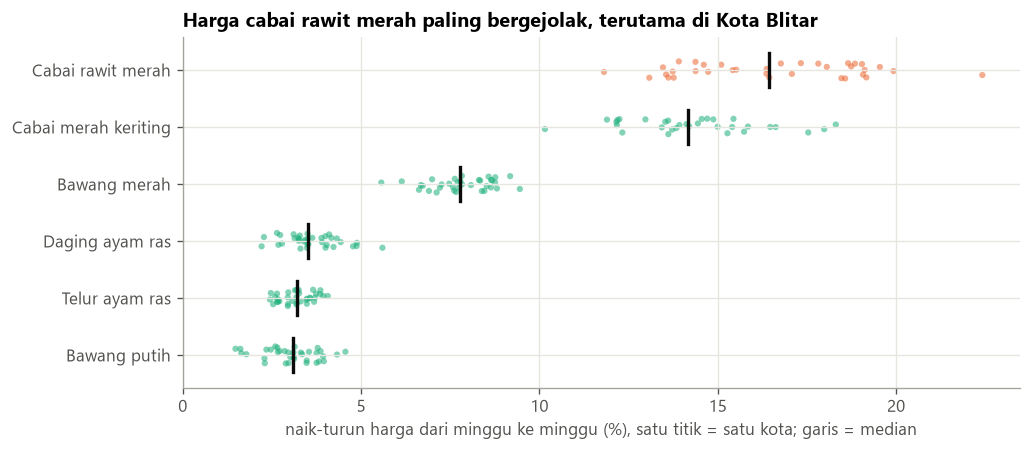

In [3]:
figs = V.figures(res)
gambar(figs["dotplot"])

## 2. Apakah dua ukuran gejolak sepakat?
Jika CV dan simpangan baku log-return memberi urutan seri yang mirip, pilihan ukuran tidak mengubah kesimpulan.

In [4]:
ps = res["per_seri"]
print("Korelasi peringkat (Spearman) CV vs std log-return:", round(ps[["cv", "gejolak_mingguan"]].corr(method="spearman").iloc[0, 1], 2))

Korelasi peringkat (Spearman) CV vs std log-return: 0.91


## 3. Peta kota × komoditas

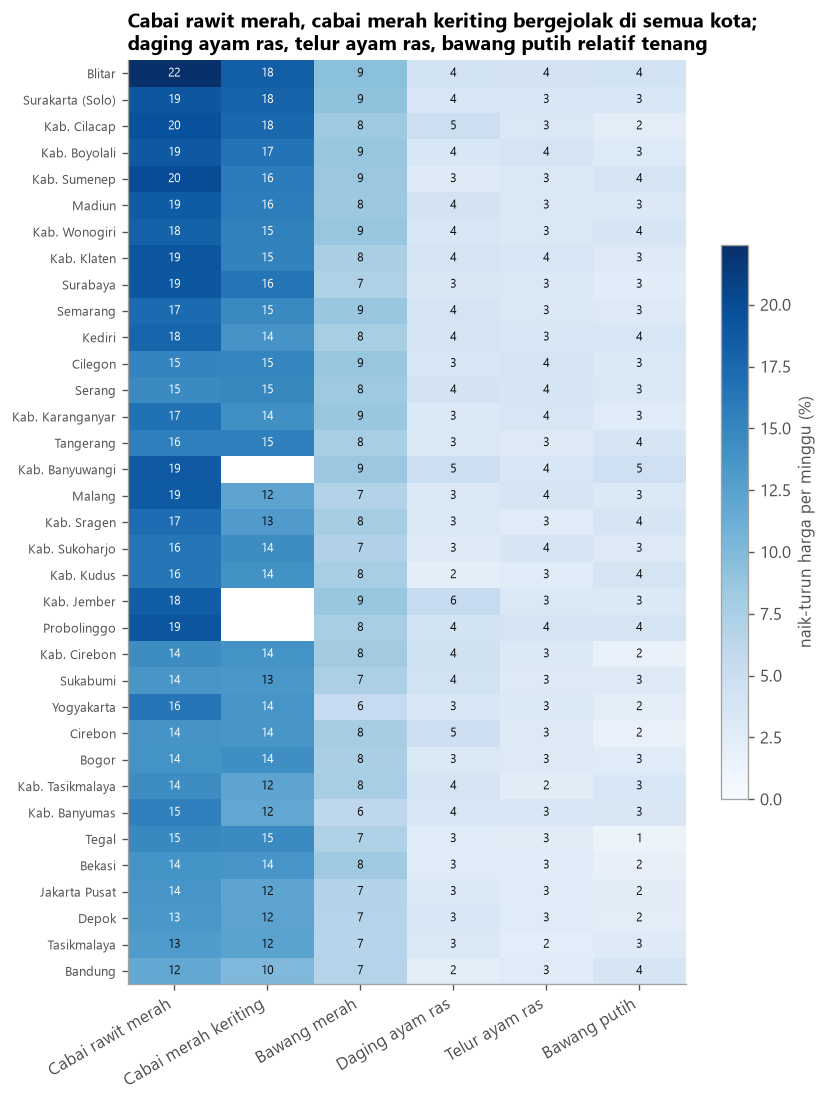

In [5]:
gambar(figs["heatmap"])

## 4. Apakah urutannya stabil dari tahun ke tahun?
Jika urutan komoditas berubah-ubah tiap tahun, peringkat di atas tidak bisa dijadikan pegangan.

In [6]:
res["per_tahun"]

tahun,kualitas,2023,2024,2025,2026
0,Cabai Rawit Merah,0.121,0.174,0.187,0.149
1,Cabai Merah Keriting,0.139,0.159,0.147,0.123
2,Bawang Merah Ukuran Sedang,0.085,0.082,0.086,0.060
3,Bawang Putih Ukuran Sedang,0.032,0.020,0.024,0.038
4,Daging Ayam Ras Segar,0.031,0.034,0.032,0.043
5,Telur Ayam Ras Segar,0.028,0.033,0.031,0.033


## 5. Pasar tradisional vs pasar modern (pembanding, dengan catatan)
Pasar modern tampak lebih tenang, tetapi lihat porsi minggu tanpa perubahan sama sekali: sebagian besar perbedaan berasal
dari cara pencatatan, bukan harga yang benar-benar stabil.

In [7]:
res["banding"]

,kualitas,gejolak_median_tradisional,gejolak_median_modern,porsi_minggu_tanpa_perubahan_tradisional,porsi_minggu_tanpa_perubahan_modern
0,Cabai Rawit Merah,0.164,0.110,0.054,0.400
1,Cabai Merah Keriting,0.142,0.090,0.074,0.499
2,Bawang Merah Ukuran Sedang,0.078,0.064,0.205,0.480
3,Bawang Putih Ukuran Sedang,0.031,0.041,0.442,0.624
4,Daging Ayam Ras Segar,0.035,0.034,0.192,0.616
5,Telur Ayam Ras Segar,0.032,0.030,0.201,0.220


## 6. Kota yang berulang kali paling bergejolak
Kota yang muncul di 3 besar untuk banyak komoditas bisa mencerminkan pasar setempat, tetapi juga sampel PIHPS yang kecil
(2 pasar × 2 pedagang per kota).

In [8]:
res["teratas"].groupby("kualitas").head(3).kota.value_counts().head(8).rename("muncul di 3 besar (komoditas)").to_frame()

,muncul di 3 besar (komoditas)
kota,
Kota Blitar,5
Kab. Cilacap,3
Kota Surakarta (Solo),2
Kota Cilegon,2
Kab. Banyuwangi,2
Kota Probolinggo,2
Kab. Sumenep,1
Kab. Jember,1


### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [9]:
V.write_summary(res, figs)
tampilkan_temuan("q1_gejolak.md")

**Harga cabai rawit merah paling bergejolak, terutama di Kota Blitar, Kab. Cilacap, Kab. Sumenep.**
Harganya naik-turun rata-rata 13% per minggu (median antar kota), dibanding
2% untuk bawang putih.
Tindakan: pantau cabai rawit merah, cabai merah keriting setiap minggu dan siapkan stok penyangga;
daging ayam ras, telur ayam ras, bawang putih relatif tenang dan cukup dipantau bulanan.